# Laboratório 6: MC $\epsilon$-guloso

## Importações

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.colors import ListedColormap
import seaborn as sns
from typing import Dict, Tuple, List, Union, Optional, Set
from numpy import linalg as LA
from collections import defaultdict
from tqdm.auto import tqdm

## Ambiente: Navegação no Labirinto (gridworld)

In [3]:
# Ambiente: Navegação no Labirinto (gridworld)
class AmbienteNavegacaoLabirinto:
    """
    Navegação no Labirinto (gridworld) determinístico para experimentos de aprendizado por reforço.

    Política de recompensa:
    - A recompensa é calculada com base na tentativa de movimento (s, a -> posição proposta), antes de aplicar rebote por sair da grade ou por entrada proibida em bad_states.
    - Se a tentativa mira fora da grade: r_boundary
    - Se mira um bad_state: r_bad
    - Se mira um target_state: r_target
    - Caso contrário: r_other

    Terminação:
    - Por padrão, o ambiente não encerra episódios automaticamente (target_states/bad_states não são estados terminais).
    """

    def __init__(
        self,
        world_size: Tuple[int, int],
        bad_states: List[Tuple[int, int]],
        target_states: List[Tuple[int, int]],
        allow_bad_entry: bool = False,
        rewards: Optional[List[float]] = None
    ) -> None:
        """
        Inicializa o ambiente de navegação em labirinto.

        Parâmetros
        ----------
        world_size : (n_linhas, n_colunas)
            Dimensões da grade.
        bad_states : lista de (linha, coluna)
            Coordenadas dos estados com penalidade.
        target_states : lista de (linha, coluna)
            Coordenadas dos estados-alvo.
        allow_bad_entry : bool
            Se False, impede entrada em bad_states (rebote para o estado atual).
        rewards : [r_boundary, r_bad, r_target, r_other]
            Recompensas possíveis. Se None, usa [-1, -1, 1, 0].
        """
        if rewards is None:
            rewards = [-1, -1, 1, 0]

        self.n_rows, self.n_cols = world_size   # dimensões da grade do labirinto
        self.bad_states = set(bad_states)       # estados com penalidade alta
        self.target_states = set(target_states) # estados com recompensa alta
        self.allow_bad_entry = allow_bad_entry  # se o agente pode entrar em estados ruins

        # Validações
        for st in self.bad_states | self.target_states:
            if not (0 <= st[0] < self.n_rows and 0 <= st[1] < self.n_cols):
                raise ValueError(f"Estado {st} fora dos limites.")
        if self.bad_states & self.target_states:
            raise ValueError("bad_states e target_states devem ser disjuntos.")

        # Recompensas definidas para cada tipo de transição
        self.r_boundary = rewards[0]    # tentar sair da grade
        self.r_bad      = rewards[1]    # transição para estado ruim
        self.r_target   = rewards[2]    # transição para estado alvo
        self.r_other    = rewards[3]    # demais transições

        # Espaço de ações: dicionário com deslocamentos (linha, coluna)
        self.action_space = {
            0: (-1, 0),  # cima
            1: (1, 0),   # baixo
            2: (0, -1),  # esquerda
            3: (0, 1),   # direita
            4: (0, 0)    # permanecer no mesmo estado
        }

        # Espaço de recompensas: lista de recompensas possíveis
        self.recompensas_possiveis = np.array(sorted(set(rewards)))
        self.reward_map = {r: i for i, r in enumerate(self.recompensas_possiveis)}

        # número total de estados
        self.n_states = self.n_rows * self.n_cols

        # número total de ações
        self.n_actions = len(self.action_space)

        # número total de recompensas possíveis
        self.n_rewards = self.recompensas_possiveis.shape[0]

        # Tensor de probabilidades de transição: P(s'|s,a)
        self.state_transition_probabilities = np.zeros((self.n_states, self.n_states, self.n_actions))

        # Tensor de probabilidade de recompensas: P(r|s,a)
        self.reward_probabilities = np.zeros((self.n_rewards, self.n_states, self.n_actions))

        # Matriz de recompensa imediata (determinística): recompensa[s, a] = r
        self.recompensas_imediatas = np.zeros((self.n_states, self.n_actions))

        # Matriz de transição de estados (determinística): transicao[s, a] = s'
        self.transicao_de_estados = np.zeros((self.n_states, self.n_actions), dtype=int)

        self.agent_pos = (0, 0)  # posição inicial do agente

        self._init_dynamics()  # inicializa as dinâmicas de transição e recompensa


    def __repr__(self) -> str:
        return (f"AmbienteNavegacaoLabirinto({self.n_rows}x{self.n_cols}, "
                f"bad={len(self.bad_states)}, target={len(self.target_states)}, "
                f"allow_bad_entry={self.allow_bad_entry}, agent_pos={self.agent_pos})")


    def __str__(self) -> str:
        return self.render(as_string=True)


    def reset(self) -> Tuple[int, int]:
        """
        Reinicia a posição do agente para o estado inicial (0, 0).

        Retorna
        -------
        (linha, coluna) : posição inicial do agente.
        """
        self.agent_pos = (0, 0)
        return self.agent_pos


    def step(self, acao: int, *, linear: bool = False) -> Tuple[Union[int, Tuple[int, int]], float]:
        """
        Executa uma ação, atualiza a posição do agente e devolve o próximo estado.

        Parâmetros
        ----------
        acao : int
            Índice da ação (0-4).
        linear : bool, keyword-only (default=False)
            Se True, retorna o estado como índice linear {0,...,self.n_states-1}; caso contrário, retorna tupla (linha, coluna).

        Retorna
        -------
        proximo_estado : int | (int, int)
            Estado observado após a transição (com possível rebote).
        recompensa : float
            Recompensa imediata recebida.
        """
        estado_atual = self.agent_pos                                           # armazena o estado atual do agente
        proposta = self._proposta(estado_atual, acao)                           # calcula a posição proposta pela ação
        recompensa = self._compute_reward(proposta)                             # avalia a recompensa com base na tentativa
        destino = self._destino_final(estado_atual, acao)                       # aplica regras e obtém o destino após possíveis rebotes
        self.agent_pos = destino                                                # atualiza a posição interna do agente
        proximo_estado = self.state_to_index(destino) if linear else destino    # escolhe o formato da observação de saída
        return proximo_estado, recompensa                                       # retorna observação e recompensa


    def reset_to_state(self, estado: Union[Tuple[int, int], int], verificar_validade_estado: bool = True) -> Tuple[int, int]:
        """
        Teleporta o agente para `estado` sem reiniciar o episódio completo.

        Parâmetros
        ----------
        estado : (linha, coluna) | int
            Tupla de coordenadas (linha, coluna) ou índice linear (int).
        verificar_validade_estado : bool
            Se True, lança ValueError se o estado for inválido.

        Retorna
        -------
        (linha, coluna) : nova posição do agente.
        """
        # Converte índice -> tupla, se necessário
        if isinstance(estado, int):
            estado = self.index_to_state(estado)

        if verificar_validade_estado and not self._in_bounds(estado):
            raise ValueError(f"Estado {estado} fora dos limites do labirinto.")

        self.agent_pos = tuple(estado)      # mantém tupla imutável

        return self.agent_pos


    def is_bad(self, state: Union[int, Tuple[int, int]]) -> bool:
        """Retorna True se o estado for um bad_state."""
        if isinstance(state, int):
            state = self.index_to_state(state)
        return state in self.bad_states


    def is_target(self, state: Union[int, Tuple[int, int]]) -> bool:
        """Retorna True se o estado for um target_state."""
        if isinstance(state, int):
            state = self.index_to_state(state)
        return state in self.target_states


    def state_to_index(self, estado: Tuple[int, int]) -> int:
        """
        Converte coordenada (linha, coluna) para índice linear no intervalo [0, n_states-1].
        """
        linha, coluna = estado
        return linha * self.n_cols + coluna


    def index_to_state(self, indice: int) -> Tuple[int, int]:
        """
        Converte índice linear  no intervalo [0, n_states-1] para coordenada (linha, coluna).
        """
        return divmod(indice, self.n_cols)  # (linha, coluna) = (indice // self.n_cols, indice % self.n_cols)


    def enumerate_states(self) -> List[int]:
        """Retorna a lista de índices lineares de todos os estados [0, ..., n_states - 1]."""
        return list(range(self.n_states))


    def enumerate_actions(self) -> List[int]:
        """Retorna a lista de índices das ações disponíveis [0, ..., n_actions - 1]."""
        return list(self.action_space.keys())


    def render(
        self,
        *,
        as_string: bool = True,
        show_coords: bool = False,
        legend: bool = True,
        chars: dict | None = None
    ) -> str:
        """
        Renderização ASCII do grid.
        - A: agente, B: bad, T: target, .: vazio
        - show_coords: mostra índices de linha/coluna
        - legend: inclui legenda ao final
        - chars: permite customizar símbolos (keys: 'agent','bad','target','empty')
        """
        if chars is None:
            chars = {"agent": "A", "bad": "B", "target": "T", "empty": "."}

        linhas = []

        # cabeçalho de colunas
        if show_coords:
            header = "    " + " ".join(f"{c:2d}" for c in range(self.n_cols))
            linhas.append(header)
            linhas.append("    " + "--" * self.n_cols)

        # monta o grid linha a linha
        for r in range(self.n_rows):
            row_syms = []
            for c in range(self.n_cols):
                sym = chars["empty"]
                if (r, c) in self.bad_states:
                    sym = chars["bad"]
                if (r, c) in self.target_states:
                    sym = chars["target"]
                if self.agent_pos == (r, c):
                    sym = chars["agent"]
                row_syms.append(sym)

            linha_str = " ".join(row_syms)
            if show_coords:
                linhas.append(f"{r:2d} | {linha_str}")
            else:
                linhas.append(linha_str)

        # legenda
        if legend:
            linhas.append("")
            linhas.append(f"Legenda: {chars['agent']}=agente, {chars['bad']}=bad, "
                        f"{chars['target']}=target, {chars['empty']}=vazio")

        out = "\n".join(linhas)
        return out if as_string else print(out)


    def plot_labirinto(
        self,
        ax=None,
        titulo: str = "Visualização do Labirinto",
        cbar: bool = False,
        mostrar_indices: bool = True,
        base: int = 0,
    ):
        """
        Visualiza o labirinto.

        Representa:
        - Estado neutro: branco
        - Estado ruim: laranja
        - Estado alvo: ciano

        Parâmetros
        ----------
        ax : matplotlib.axes.Axes, opcional
            Eixo onde desenhar. Se None, cria uma nova figura.
        titulo : str, opcional
            Título do gráfico.
        cbar : bool, opcional (default=False)
            Exibe (True) ou oculta (False) a barra de cores.
        mostrar_indices : bool, opcional (default=True)
            Escreve o índice linear no canto superior esquerdo de cada célula.
        base : int, opcional (default=1)
            Primeiro número dos eixos. Use 1 para numerar de 1 a n, ou 0 para
            alinhar com os índices lineares.

        Retorna
        -------
        ax : matplotlib.axes.Axes
            Eixo com o heatmap.
        """
        # Cria matriz com valores padrão (0 = neutro)
        matriz = np.zeros((self.n_rows, self.n_cols), dtype=int)

        # marca estados
        for (r, c) in self.bad_states:
            matriz[r, c] = 1   # ruim
        for (r, c) in self.target_states:
            matriz[r, c] = 2   # alvo

        # cores: branco=neutro, laranja=ruim, ciano=alvo
        cmap = ListedColormap(["white", "orange", "cyan"])

        fig = None
        if ax is None:
            fig, ax = plt.subplots(figsize=(self.n_cols, self.n_rows))

        ax = sns.heatmap(
            matriz,
            cmap=cmap,
            cbar=cbar,
            linewidths=1.0,
            linecolor="black",
            square=True,
            ax=ax
        )

        # numeração dos eixos, com as colunas no topo
        ax.set_xticks(np.arange(self.n_cols) + 0.5)
        ax.set_xticklabels([str(c + base) for c in range(self.n_cols)], rotation=0)
        ax.set_yticks(np.arange(self.n_rows) + 0.5)
        ax.set_yticklabels([str(r + base) for r in range(self.n_rows)], rotation=0)
        ax.xaxis.set_ticks_position("top")
        ax.tick_params(length=0, colors="dimgray")

        # índice linear no canto superior esquerdo de cada célula
        if mostrar_indices:
            for r in range(self.n_rows):
                for c in range(self.n_cols):
                    ax.text(
                        c + 0.06, r + 0.06, f"s{r * self.n_cols + c}",
                        ha="left", va="top", fontsize=8, color="dimgray"
                    )

        # bordas externas
        for side in ("left", "right", "top", "bottom"):
            ax.spines[side].set_visible(True)
            ax.spines[side].set_linewidth(1.0)
            ax.spines[side].set_edgecolor("black")

        ax.set_title(titulo)

        if fig is not None:
            plt.tight_layout()
            plt.show()

        return ax


    def _init_dynamics(self):
        """
        Preenche as matrizes de transição e recompensa com base na estrutura do ambiente e regras de movimentação.
        """

        self.recompensas_imediatas.fill(0.0)
        self.transicao_de_estados.fill(0)
        self.state_transition_probabilities.fill(0.0)
        self.reward_probabilities.fill(0.0)

        for s in self.enumerate_states():                                   # percorre todos os estados (índices lineares)
            estado_atual = self.index_to_state(s)                           # converte índice para (linha, coluna)
            for a in self.enumerate_actions():                              # percorre todas as ações disponíveis
                proposta = self._proposta(estado_atual, a)                  # calcula a posição proposta pela ação
                r = self._compute_reward(proposta)                          # avalia a recompensa da tentativa de movimento
                destino = self._destino_final(estado_atual, a)              # obtém destino após aplicar regras de rebote
                s_next = self.state_to_index(destino)                       # converte destino para índice linear

                self.recompensas_imediatas[s, a] = r                        # registra r(s, a) na matriz de recompensas imediatas
                self.transicao_de_estados[s, a] = s_next                    # registra T(s, a) = s' na matriz de transições

                self.state_transition_probabilities[s_next, s, a] = 1.0     # define P(s'|s, a) = 1 (ambiente determinístico)
                self.reward_probabilities[self.reward_map[r], s, a] = 1.0   # define P(r |s, a) = 1 (ambiente determinístico)


    def _proposta(self, state: Tuple[int, int], acao: int) -> Tuple[int, int]:
        """Retorna a posição proposta (antes de qualquer rebote)."""
        dl, dc = self.action_space[acao]
        return (state[0] + dl, state[1] + dc)


    def _destino_final(self, state: Tuple[int, int], acao: int) -> Tuple[int, int]:
        """
        Aplica as regras de rebote: fora da grade => rebote;
        bad_state com allow_bad_entry=False => rebote; caso contrário segue para a proposta.
        """
        proposta = self._proposta(state, acao)
        if not self._in_bounds(proposta):
            return state
        if (not self.allow_bad_entry) and self.is_bad(proposta):
            return state
        return proposta


    def _in_bounds(self, posicao: Tuple[int, int]) -> bool:
        """
        Verifica se uma posição está dentro dos limites do labirinto.

        Parâmetros
        ----------
        posicao : (linha, coluna)

        Retorna
        -------
        bool : True se dentro da grade, False caso contrário.
        """
        linha, coluna = posicao
        return 0 <= linha < self.n_rows and 0 <= coluna < self.n_cols


    def _compute_reward(self, destino: Tuple[int, int]) -> float:
        """
        Calcula a recompensa da tentativa de transição para 'destino'.

        Regras
        ------
        - Se 'destino' está fora da grade: r_boundary
        - Se 'destino' é bad_state: r_bad
        - Se 'destino' é target_state: r_target
        - Caso contrário: r_other
        """
        if not self._in_bounds(destino):
            return self.r_boundary
        elif self.is_bad(destino):
            return self.r_bad
        elif self.is_target(destino):
            return self.r_target
        else:
            return self.r_other

## Funções auxiliares para visualização

In [4]:
def _prepare_grid(env, ax=None, draw_cells=True, mostrar_indices=True):
    """
    Configura o grid. Se 'ax' não for passado, cria 'fig, ax'; caso contrário retorna 'fig=None, ax'.

    Segue o mesmo estilo de plot_labirinto: estado ruim em laranja, alvo em ciano,
    linhas e colunas numeradas a partir de 0 (colunas no topo) e índice linear no
    canto superior esquerdo de cada célula.
    """
    fig = None
    if ax is None:
        fig, ax = plt.subplots(figsize=(env.n_cols, env.n_rows))

    ax.set_xlim(0, env.n_cols)
    ax.set_ylim(0, env.n_rows)
    ax.set_aspect('equal')
    ax.invert_yaxis()

    # numeração dos eixos a partir de 0, com as colunas no topo
    ax.set_xticks(np.arange(env.n_cols) + 0.5)
    ax.set_xticklabels([str(c) for c in range(env.n_cols)], rotation=0)
    ax.set_yticks(np.arange(env.n_rows) + 0.5)
    ax.set_yticklabels([str(r) for r in range(env.n_rows)], rotation=0)
    ax.xaxis.set_ticks_position("top")
    ax.tick_params(length=0, colors="dimgray")

    if draw_cells:
        for r in range(env.n_rows):
            for c in range(env.n_cols):
                cell = (r, c)
                if cell in env.bad_states:
                    color = 'orange'
                elif cell in env.target_states:
                    color = 'cyan'
                else:
                    color = 'white'
                rect = patches.Rectangle((c, r), 1, 1, facecolor=color, edgecolor='black', linewidth=1.0)
                ax.add_patch(rect)

                # índice linear no canto superior esquerdo de cada célula
                if mostrar_indices:
                    ax.text(
                        c + 0.06, r + 0.06, f"s{r * env.n_cols + c}",
                        ha="left", va="top", fontsize=8, color="dimgray"
                    )

    # bordas externas
    for side in ("left", "right", "top", "bottom"):
        ax.spines[side].set_visible(True)
        ax.spines[side].set_linewidth(1.0)
        ax.spines[side].set_edgecolor("black")

    return fig, ax

def _coerce_policy(env, policy):
    """
    Normaliza a política para o formato dict[(r,c)] -> vetor de probabilidades.
    Aceita:
      - dict[(r,c)] -> ação
      - dict[(r,c)] -> vetor de probabilidades
      - Pi ndarray (n_estados, n_acoes)

    Políticas determinísticas viram vetores one-hot, de modo que o mesmo
    desenho serve para políticas determinísticas e estocásticas.
    """
    n_acoes = env.n_actions

    # caso 1: matriz Pi (ndarray)
    if isinstance(policy, np.ndarray):
        return {env.index_to_state(s): np.asarray(policy[s], dtype=float) for s in range(env.n_states)}

    # caso 2: dicionário
    sample_val = next(iter(policy.values()))
    if isinstance(sample_val, np.ndarray):
        return {pos: np.asarray(probs, dtype=float) for pos, probs in policy.items()}
    else:
        return {pos: np.eye(n_acoes)[int(a)] for pos, a in policy.items()}

def plot_policy(env, policy, ax=None, titulo="Política",
                estados_destacados=None, cor_destaque="red", limiar=0.02):
    """
    Desenha setas/círculos de uma política. 'policy' pode ser:
      - dict[(r,c)] -> ação
      - dict[(r,c)] -> vetor de probabilidades
      - ndarray com shape (n_estados, n_acoes)

    A opacidade de cada seta é a probabilidade da ação: pi(a|s) = 1 dá uma seta
    preta e pi(a|s) = 0.2 dá uma seta clara. Políticas determinísticas aparecem
    como uma única seta preta por estado, e políticas estocásticas mostram todas
    as ações com probabilidade relevante.

    estados_destacados : lista de (linha, coluna), opcional
        Estados cujas setas serão desenhadas em 'cor_destaque' em vez de preto.
        Útil para marcar, por exemplo, os estados em que a ação não é ótima.
    cor_destaque : str, opcional (default="red")
        Cor das setas dos estados destacados.
    limiar : float, opcional (default=0.02)
        Probabilidade abaixo da qual a ação não é desenhada.
    """
    fig, ax = _prepare_grid(env, ax=ax)

    policy_dict = _coerce_policy(env, policy)
    destacados = set(map(tuple, estados_destacados)) if estados_destacados is not None else set()
    lw = 1.5
    L = 0.3                       # comprimento da seta (fixo)
    DELTA = {0: (0, -1),          # cima
             1: (0, 1),           # baixo
             2: (-1, 0),          # esquerda
             3: (1, 0)}           # direita

    for (r, c), probs in policy_dict.items():
        x, y = c + 0.5, r + 0.5
        color = cor_destaque if (r, c) in destacados else 'black'

        for action, (dx, dy) in DELTA.items():
            p = float(probs[action])
            if p < limiar:
                continue
            ax.arrow(x, y, dx=dx * L, dy=dy * L, head_width=0.2, head_length=0.2,
                     fc=color, ec=color, linewidth=lw, alpha=max(p, 0.10))

        p_ficar = float(probs[4])  # ação 4: ficar
        if p_ficar >= limiar:
            circ = patches.Circle((x, y), 0.1, edgecolor=color, facecolor='none',
                                  linewidth=lw, alpha=max(p_ficar, 0.10))
            ax.add_patch(circ)

    ax.set_title(titulo)
    if fig is not None:
        plt.tight_layout()
        plt.show()
    return ax

def plot_tabular(
    data,
    kind: str = "Q",          # "Q" (valores de ação), "Pi" (política), "V" (valores de estado), "VISITAS" (número de visitas)
    ambiente=None,            # necessário quando kind="V" para reshape
    ax=None,
    cbar: bool = True,
    fmt: str = ".1f",
    center_zero: bool = True  # só relevante para "Q" e "V"
):
    """
    Plota matrizes tabulares de RL em formato de heatmaps (mapas de calor).
    Esta função cobre 5 casos:
    1. kind="Q": heatmap de Q(s, a) com ações nas linhas e estados nas colunas.
    2. kind="Pi": heatmap de Pi(a|s) (probabilidades) com ações nas linhas e estados nas colunas.
    3. kind="V": heatmap de V(s) no grid (n_rows x n_cols) do ambiente.
    4. kind="VISITAS": heatmap do número de visitas visitas(s,a) com ações nas linhas e estados nas colunas.
    5. kind="VISITAS_ESTADO": heatmap do número de visitas por estado, somado sobre as ações,
       no grid (n_rows x n_cols) do ambiente. Útil para ver quais estados nunca foram visitados.

    Parameters
    ----------
    data : ndarray
        Dados a serem plotados.
        - Para kind="Q", "Pi", "VISITAS" ou "VISITAS_ESTADO": array 2D com shape (n_estados, n_acoes).
        - Para kind="V": array 1D com shape (n_estados,) que será remodelado para (ambiente.n_rows, ambiente.n_cols).
    kind : {"Q", "Pi", "V", "VISITAS", "VISITAS_ESTADO"}, default="Q"
        Tipo do plot:
        - "Q" usa paleta divergente centrada em zero.
        - "Pi" usa paleta sequencial no intervalo [0, 1].
        - "V" plota o valor de estado no grid do ambiente.
        - "VISITAS" e "VISITAS_ESTADO" usam paleta sequencial a partir de zero.
    ambiente : object, optional
        Necessário quando kind="V" ou kind="VISITAS_ESTADO". Deve expor n_rows e n_cols para o reshape.
    ax : matplotlib.axes.Axes, optional
        Eixo onde o heatmap será desenhado. Se None, uma nova figura/eixo é criado.
    cbar : bool, default=True
        Se True, exibe a barra de cores (colorbar).
    fmt : str, default=".1f"
        Formatação dos valores anotados em cada célula do heatmap. Para kind="VISITAS"
        e kind="VISITAS_ESTADO" o padrão passa a ".0f", já que as contagens são inteiras.
    center_zero : bool, default=True
        Quando kind é "Q" ou "V", centraliza a escala de cores em zero (vmin=-absmax, vmax=absmax). Ignorado para "Pi".

    Returns
    -------
    ax : matplotlib.axes.Axes
        Eixo contendo o heatmap resultante.
    """
    kind = kind.upper()

    xlabel = {"V": "Colunas", "PI": "Estados", "Q": "Estados", "VISITAS": "Estados",
              "VISITAS_ESTADO": "Colunas"}
    ylabel = {"V": "Linhas", "PI": "Ações", "Q": "Ações", "VISITAS": "Ações",
              "VISITAS_ESTADO": "Linhas"}
    title  = {"V": "Valores de Estado (V(s))",
              "PI": r"Política ($\pi(a|s)$ transposta)",
              "Q": "Valores de ação (Q(s, a) transposta)",
              "VISITAS":  "Número de visitas visitas(s, a) (transposta)",
              "VISITAS_ESTADO": "Número de visitas por estado"}

    fig = None

    #  V(s): precisa do shape do grid
    match kind:
        case "V":

            if ambiente is None:
                raise ValueError("Para kind='V', passe 'ambiente' para reshape (n_rows, n_cols).")

            M = data.reshape(ambiente.n_rows, ambiente.n_cols)

            if ax is None:
                fig, ax = plt.subplots(figsize=(ambiente.n_cols, ambiente.n_rows))

            if center_zero:
                vmax = float(np.abs(M).max())
                vmin = -vmax
            else:
                vmin = float(M.min())
                vmax = float(M.max())

            cmap, square = "bwr", True

        case "PI" | "Q":

            # Q(s,a) e Pi(a|s): ações nas linhas, estados nas colunas
            M = data.T  # data: (n_estados, n_acoes) -> transposto para (n_acoes, n_estados)
            n_acoes, n_estados = M.shape

            if ax is None:
                fig, ax = plt.subplots(figsize=(n_estados, n_acoes))

            if kind == "PI":
                cmap = "Blues";
                vmin, vmax = 0.0, 1.0
            else:  # "Q"
                cmap = "bwr"
                if center_zero:
                    vmax = float(np.abs(M).max())
                    vmin = -vmax
                else:
                    vmin = float(M.min())
                    vmax = float(M.max())

            square = False

        case "VISITAS":
            # visitas(s,a): visitas, ações nas linhas, estados nas colunas
            M = data.T
            n_acoes, n_estados = M.shape

            if ax is None:
                fig, ax = plt.subplots(figsize=(n_estados, n_acoes))

            cmap = "Oranges"     # paleta sequencial para contagens
            vmin = 0.0
            vmax = float(M.max()) if M.max() > 0 else 1.0
            square = False

            # contagens são inteiras: evita exibir "810176.0"
            if fmt == ".1f":
                fmt = ".0f"

        case "VISITAS_ESTADO":
            # visitas(s): soma sobre as ações, desenhada no grid do ambiente
            if ambiente is None:
                raise ValueError("Para kind='VISITAS_ESTADO', passe 'ambiente' para reshape (n_rows, n_cols).")

            M = data.sum(axis=1).reshape(ambiente.n_rows, ambiente.n_cols)

            if ax is None:
                fig, ax = plt.subplots(figsize=(ambiente.n_cols, ambiente.n_rows))

            cmap = "Oranges"
            vmin = 0.0
            vmax = float(M.max()) if M.max() > 0 else 1.0
            square = True

            if fmt == ".1f":
                fmt = ".0f"

        case _:
            raise ValueError(
                f"kind desconhecido: {kind!r} (use 'Q', 'Pi', 'V', 'VISITAS' ou 'VISITAS_ESTADO')."
            )


    ax = sns.heatmap(
        data=M,
        annot=True,
        fmt=fmt,
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        cbar=cbar,
        square=square,
        linewidths=0.5,
        linecolor="gray",
        ax=ax
    )

    ax.set_xlabel(xlabel[kind])
    ax.set_ylabel(ylabel[kind])
    ax.set_title(title[kind])

    # bordas externas
    for side in ("left", "right", "top", "bottom"):
        ax.spines[side].set_visible(True)
        ax.spines[side].set_linewidth(0.5)
        ax.spines[side].set_edgecolor("gray")

    # rótulos
    if kind in ("Q", "PI", "VISITAS"):
        ax.set_xticks(np.arange(n_estados) + 0.5)
        ax.set_xticklabels([f"s{i}" for i in range(n_estados)], rotation=0)
        ax.set_yticks(np.arange(n_acoes) + 0.5)
        ax.set_yticklabels([f"a{i}" for i in range(n_acoes)], rotation=0)

    if fig is not None:
        plt.tight_layout()
        plt.show()

    return ax

def plot_visitas_log(n_visitas, ax=None):
    """
    Gera um gráfico de dispersão com escala logarítmica no eixo y
    mostrando o número de visitas para cada par (s,a).

    Parâmetros
    ----------
    n_visitas : np.ndarray
        Matriz de número de visitas de shape (n_states, n_actions).
    ax : matplotlib.axes.Axes, opcional
        Eixo onde desenhar. Se None, cria uma nova figura.

    Retorna
    -------
    ax : matplotlib.axes.Axes
        Eixo contendo o gráfico resultante.
    """
    n_states, n_actions = n_visitas.shape
    x = np.arange(n_states * n_actions)  # índice linear do par (s,a)
    y = n_visitas.flatten()              # número de visitas

    fig = None
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 4))

    ax.scatter(x, y, s=10, alpha=0.7)
    ax.set_yscale('log')
    ax.set_xlabel("Índice linear do par (s,a)")
    ax.set_ylabel("Número de visitas ao par (s,a)")
    ax.set_title("Frequência de visitas (escala log)")
    ax.grid(alpha=0.3)

    if fig is not None:
        plt.tight_layout()
        plt.show()

    return ax

## Ambiente: nova instância

O labirinto é o mesmo dos Laboratórios 1, 2, 4 e 5, e a interação também: `reset_to_state(estado)` posiciona o agente num estado, dado como tupla `(linha, coluna)` ou como índice linear, e `step(acao, linear=True)` executa uma ação e devolve o par `(proximo_estado, recompensa)`.

**Atenção a uma mudança nas recompensas.** Neste laboratório $r_{\text{bad}} = -1$, e não $-10$ como nos anteriores.

In [5]:
ambiente = AmbienteNavegacaoLabirinto(
        world_size=(5, 5),
        bad_states=[(1, 1), (1, 2), (2, 2), (3, 1), (3, 3), (4, 1)],
        target_states=[(3, 2)],
        allow_bad_entry=True,
        rewards=[-1, -1, 1, 0]
    )

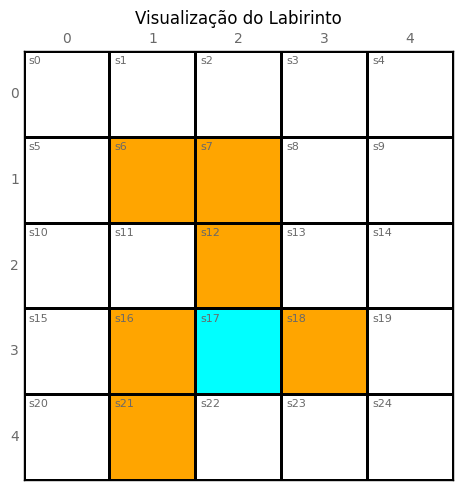

In [6]:
_ = ambiente.plot_labirinto()

## MC $\epsilon$-guloso

O MC com inícios exploratórios do Laboratório 5 resolvia o problema da exploração impondo o par inicial: cada episódio começava num $(s_0, a_0)$ sorteado, e a partir daí seguia uma política determinística. Essa exigência é forte, porque supõe que se pode colocar o agente em qualquer estado com qualquer ação, o que pode não ser possível fora de um simulador.

O MC $\epsilon$-guloso troca essa exigência por outra: a política deixa de ser determinística e passa a ser **$\epsilon$-suave**, ou seja, atribui probabilidade positiva a todas as ações em todos os estados. A exploração deixa de acontecer uma vez por episódio e passa a acontecer a cada passo.

A política melhorada não é mais totalmente gulosa. Dado $a^* = \arg\max_a Q(s,a)$, ela é

$$\pi(a \mid s) = \begin{cases}
1 - \dfrac{|\mathcal{A}| - 1}{|\mathcal{A}|}\,\epsilon, & a = a^* \\[8pt]
\dfrac{\epsilon}{|\mathcal{A}|}, & a \neq a^*
\end{cases}$$

em que $|\mathcal{A}|$ é o número de ações. Temos que:
 - $\epsilon = 0$: recupera a política gulosa determinística;
 - $\epsilon = 1$: todas as ações ficam com probabilidade $1/|\mathcal{A}|$ e a política vira uniforme.

Em ambos os casos as probabilidades somam 1.

O restante do algoritmo é igual ao do Laboratório 5: uma trajetória por episódio, varredura reversa acumulando o retorno, média de todas as visitas e melhoria imediata no estado visitado. As duas diferenças são:

1. Início livre em vez do início exploratório;
2. Passo de melhoria $\epsilon$-guloso em vez de guloso.

A implementação está dividida em duas funções: `gerar_trajetoria_epsilon`, que simula um episódio, e `mc_epsilon_guloso`, o laço externo. Implemente as duas, preenchendo os blocos marcados.

### Trajetória Monte-Carlo com horizonte fixo T

Implemente `gerar_trajetoria_epsilon`, preenchendo o bloco marcado.

A função simula um episódio de `T` passos e devolve a **trajetória**: a lista dos passos executados, na ordem em que ocorreram. Cada passo é registrado como a tupla

$$(s_t,\ a_t,\ r_{t+1})$$

ou seja, o estado em que o agente estava, a ação executada nesse estado e a recompensa recebida por ela.

**Diferença em relação ao Laboratório 5.** Lá, `gerar_trajetoria` recebia o par $(s_0, a_0)$ e forçava a ação do primeiro passo. Aqui, apenas o estado inicial é sorteado, e **todas** as ações, inclusive a do primeiro passo, vêm de `Pi`. Como `Pi` é estocástica, a ação de cada passo é sorteada segundo as probabilidades da linha correspondente, e não obtida com `argmax`.

O sorteio usa o gerador `rng`, recebido como argumento, para que a execução seja reprodutível a partir da semente. A função `rng.choice` aceita o vetor de probabilidades pelo argumento `p`.

**Atenção:**
- O estado registrado na tupla é aquele **de onde** a ação partiu, e não o estado alcançado. Registre a tupla antes de avançar para o próximo estado, e não use a mesma variável para receber o retorno de `step`.
- Sem `linear=True`, `step` devolve o próximo estado como tupla `(linha, coluna)`, que não serve para indexar `Pi`.
- `reset_to_state` só reconhece índices do tipo `int` do Python; converta com `int(...)` quando o índice vier do NumPy.

A função deve retornar `trajetoria`, uma lista de `T` tuplas.

In [7]:
def gerar_trajetoria_epsilon(
    ambiente,
    Pi: np.ndarray,
    T: int,
    rng: np.random.Generator,
) -> List[Tuple[int, int, float]]:
    """
    Gera um episódio de comprimento fixo T seguindo a política estocástica Pi.

    O estado inicial é sorteado uniformemente; a ação inicial NÃO é forçada
    (a condição de inícios exploratórios não é exigida aqui).
    Cada passo armazenado na trajetória contém a tupla (s_t, a_t, r_{t+1}).

    Parâmetros
    ----------
    ambiente : AmbienteNavegacaoLabirinto
        Instância do gridworld.
    Pi : np.ndarray, shape (n_estados, n_acoes)
        Política estocástica atual: Pi[s, a] = probabilidade de escolher a em s.
    T : int
        Horizonte fixo do episódio - número de passos do episódio (>=1).
    rng : np.random.Generator
        Gerador de números aleatórios, criado no laço externo a partir da semente.

    Retorna
    -------
    trajetoria : List[Tuple[int, int, float]]
        Lista de tamanho T com as tuplas (s_t, a_t, r_{t+1}).
    """
    if T < 1:
        raise ValueError("T deve ser >= 1.")

    # Atalhos do ambiente (shapes)
    n_estados = ambiente.n_states   # int
    n_acoes   = ambiente.n_actions  # int

    # Estado inicial sorteado uniformemente.
    estado_atual = int(rng.integers(n_estados))
    ambiente.reset_to_state(estado_atual)

    # Inicialização
    trajetoria = []

    # Loop principal: segue a política estocástica epsilon-suave
    for _ in range(T):

        # sorteia a ação segundo as probabilidades de Pi no estado atual
        # executa a ação e registra a tupla (s_t, a_t, r_{t+1})
        # avança para o estado alcançado

        # Código aqui
        acao = rng.choice(n_acoes, p=Pi[estado_atual])

        proximo_estado, recompensa = ambiente.step(acao, linear=True)

        trajetoria.append((estado_atual, acao, recompensa))

        estado_atual = int(proximo_estado)

    return trajetoria

### Laço externo

Implemente `mc_epsilon_guloso`, preenchendo os três blocos marcados. Cada iteração do laço externo corresponde a um episódio, e são `N` episódios no total.

**Bloco 1 — trajetória.** Gere o episódio com `gerar_trajetoria_epsilon`, seguindo a política `Pi` corrente e passando o gerador `rng`.

**Bloco 2 — varredura reversa.** Percorra a trajetória do último passo para o primeiro, acumulando o retorno pela relação

$$G_t = r_{t+1} + \gamma\,G_{t+1}, \qquad G_T = 0$$

Em cada passo visitado, registre a visita, acumule a soma dos retornos e atualize a estimativa:

$$Q(s_t,a_t) = \frac{\text{soma_dos_retornos}(s_t,a_t)}{\text{numero_de_visitas}(s_t,a_t)}$$

**Bloco 3 — melhoria $\epsilon$-gulosa.** Logo após atualizar $Q$, refaça a linha `Pi[s_t]` pela fórmula da seção anterior, com $a^*$ igual à ação de maior valor em `Q[s_t]`. A melhoria afeta **apenas** o estado $s_t$.

As três matrizes `Q`, `numero_de_visitas` e `soma_dos_retornos` já estão inicializadas com zeros, com shape `(n_estados, n_acoes)`, e `Pi` começa uniforme.

**Atenção:**
- Use a estratégia de **todas as visitas**: se um par $(s,a)$ aparece mais de uma vez na mesma trajetória, cada ocorrência conta.
- As três matrizes acumulam ao longo dos episódios; **não** as reinicialize dentro do laço. O retorno $G$, ao contrário, recomeça em zero a cada episódio.
- Depois da melhoria, confira que `Pi[s_t]` soma 1.

A função deve retornar `Q`, `Pi` e `numero_de_visitas` com shape `(n_estados, n_acoes)`, e `k`, o número de episódios executados.

In [8]:
def mc_epsilon_guloso(
    ambiente,
    gamma: float = 0.9,
    N: int = 20,
    T: int = 100_000,
    eps: float = 0.5,
    seed: int = 0,
) -> Tuple[np.ndarray, np.ndarray, np.ndarray, int]:
    """
    Monte Carlo epsilon-guloso no gridworld.

    Loop por episódio:
      1) Gera trajetória de comprimento fixo T seguindo a política epsilon-suave Pi;
      2) Varredura reversa acumulando o retorno G e atualizando Q(s,a) por média (todas as visitas);
      3) Melhoria de política incremental: após cada atualização de Q(s_t, a_t), torna Pi
         epsilon-gulosa em torno de argmax_a Q(s_t, a).

    Parâmetros
    ----------
    ambiente : AmbienteNavegacaoLabirinto
        Instância do gridworld.
    gamma : float
        Fator de desconto.
    N : int
        Número total de episódios.
    T : int
        Horizonte fixo (número de passos) de cada episódio.
    eps : float
        Parâmetro epsilon da política epsilon-suave (0 <= eps <= 1).
    seed : int
        Semente do gerador de números aleatórios.

    Retorna
    -------
    Q   : np.ndarray, shape (n_estados, n_acoes)
        Estimativas finais de Q(s,a).
    Pi  : np.ndarray, shape (n_estados, n_acoes)
        Política epsilon-suave resultante.
    numero_de_visitas : np.ndarray, shape (n_estados, n_acoes)
        Contagem de visitas por par (s,a).
    k   : int
        Número de episódios executados (sempre igual a N: não há parada antecipada).
    """

    # Reprodutibilidade
    rng = np.random.default_rng(seed)

    # Atalhos
    n_estados = ambiente.n_states
    n_acoes   = ambiente.n_actions

    # Inicializações
    Q                 = np.zeros((n_estados, n_acoes), dtype=float)
    soma_dos_retornos = np.zeros((n_estados, n_acoes), dtype=float)
    numero_de_visitas = np.zeros((n_estados, n_acoes), dtype=float)

    # Política inicial epsilon-suave: uniforme (sem preferência inicial)
    Pi = np.full((n_estados, n_acoes), 1.0 / n_acoes, dtype=float)

    for k in tqdm(range(1, N + 1), desc="Episódios (MC epsilon-guloso)"):

        # 1. Gera a trajetória sob a política epsilon-suave corrente

        # Código aqui
        trajetoria = gerar_trajetoria_epsilon(ambiente, Pi, T, rng)

        # 2. Varredura reversa: calcula o retorno G de cada passo e atualiza
        #    numero_de_visitas, soma_dos_retornos e Q

        # Código aqui
        G = 0.0
        for s_t, a_t, r in reversed(trajetoria):
            G = r + gamma * G

            numero_de_visitas[s_t, a_t] += 1.0
            soma_dos_retornos[s_t, a_t] += G
            Q[s_t, a_t] = soma_dos_retornos[s_t, a_t] / numero_de_visitas[s_t, a_t]

            # 3. Melhoria epsilon-gulosa APENAS no estado s_t
            #    (dentro do laço da varredura reversa, logo após atualizar Q)

            # Código aqui
            a_star = np.argmax(Q[s_t])

            Pi[s_t] = eps / n_acoes

            Pi[s_t, a_star] += 1.0 - eps

    return Q, Pi, numero_de_visitas, k

## Experimento

### Simulação


A célula abaixo executa o MC $\epsilon$-guloso sobre a instância do baseline, com os parâmetros indicados. São `N` episódios de `T` passos cada, ou seja, `N`$\times$`T` passos ao todo; a barra de progresso acompanha os episódios.

O argumento `seed` fixa o gerador que sorteia o estado inicial de cada episódio e as ações ao longo dele. Com a mesma semente, a execução é reprodutível.

In [9]:
Q, Pi, numero_de_visitas, k = mc_epsilon_guloso(
    ambiente,    # gridworld
    gamma=0.9,   # fator de desconto
    N=20,        # número total de episódios
    T=100_000,   # comprimento fixo de cada episódio
    eps=0.5,     # parâmetro epsilon da política epsilon-suave
    seed=0       # semente para a reprodutibilidade
)

Episódios (MC epsilon-guloso):   0%|          | 0/20 [00:00<?, ?it/s]

Os valores de estado da política encontrada saem de $Q$ e de `Pi`:

$$V(s) = \sum_a \pi(a \mid s)\, Q(s,a)$$

ou seja, a média dos valores de ação ponderada pelas probabilidades da política. Diferentemente do Laboratório 5, essa soma não se reduz a $\max_a Q(s,a)$, porque aqui a política é estocástica e todas as ações entram na média com o seu peso.

In [10]:
# Derivar V a partir de Q:
V = np.sum(Pi * Q, axis=1)

### Visualização

As figuras são geradas usando as funções auxiliares definidas anteriormente. `plot_tabular` produz os heatmaps de $Q(s,a)$, $\pi(a\mid s)$, $V(s)$ e do número de visitas, selecionados pelo argumento `kind`, e `plot_visitas_log` mostra as contagens por par $(s,a)$ em escala logarítmica.

**Como ler a política estocástica.** `plot_policy` desenha uma seta por ação, e a **opacidade da seta é a probabilidade da ação**: uma ação de probabilidade 1 aparece preta, uma de probabilidade 0.2 aparece clara, e ações abaixo de 0.02 não são desenhadas. O círculo representa a ação de permanecer no estado e segue a mesma regra. Assim, uma política determinística aparece como uma única seta preta por estado, como nos laboratórios anteriores, e uma política $\epsilon$-suave mostra as cinco ações com tons diferentes.

Vale notar o caso $\epsilon = 1$: todas as ações ficam com probabilidade $1/5$, as cinco setas saem igualmente claras e a figura mostra que não há preferência nenhuma.

As funções `plot_tabular`, `plot_policy` e `plot_visitas_log` aceitam o argumento `ax`, que indica em qual painel de uma figura o gráfico deve ser desenhado. Isso permite reunir resultados lado a lado, como pedem os itens da tarefa. O exemplo abaixo desenha $V(s)$ e a política da configuração base numa mesma figura:

```python
fig, axs = plt.subplots(1, 2, figsize=(10, 5))   # uma linha, dois painéis
plot_tabular(V, kind="V", ambiente=ambiente, center_zero=False, ax=axs[0])
axs[0].set_title("V(s), eps = 0.5")
plot_policy(ambiente, Pi, ax=axs[1])
axs[1].set_title("Política, eps = 0.5")
plt.tight_layout()
plt.show()
```

Quando recebem `ax`, as funções não chamam `plt.show()`: a figura é exibida uma única vez, ao final, com todos os painéis. Os títulos são redefinidos com `set_title` depois de cada chamada, para identificar o valor do parâmetro em cada painel. Para vários valores de um parâmetro, crie uma grade com `plt.subplots(2, n, figsize=(5 * n, 10))`, em que `n` é o número de valores, e desenhe o resultado do $j$-ésimo valor em `axs[0, j]` e `axs[1, j]`.

**Atenção a dois pontos.** Cada heatmap calcula sua escala de cores a partir dos próprios valores, então a mesma cor pode representar números diferentes em painéis diferentes; ao comparar painéis, use os números anotados nas células. E a escala logarítmica de `plot_visitas_log` não representa o zero, de modo que pares nunca visitados simplesmente não aparecem no gráfico de dispersão; para enxergá-los, use `kind="VISITAS"`, no caso dos pares, ou `kind="VISITAS_ESTADO"`, no caso dos estados.

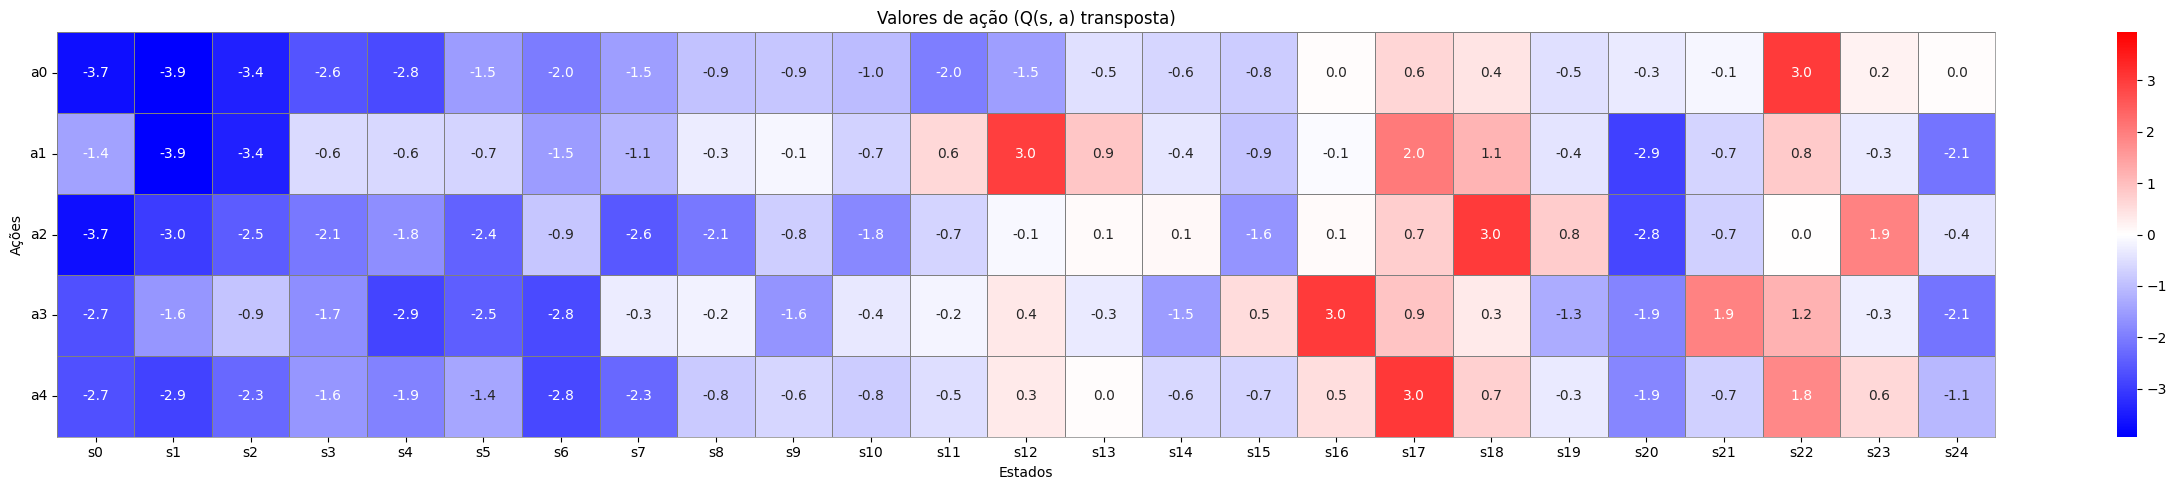

In [11]:
# Q: ndarray (n_estados, n_acoes)
_ = plot_tabular(Q, kind="Q")

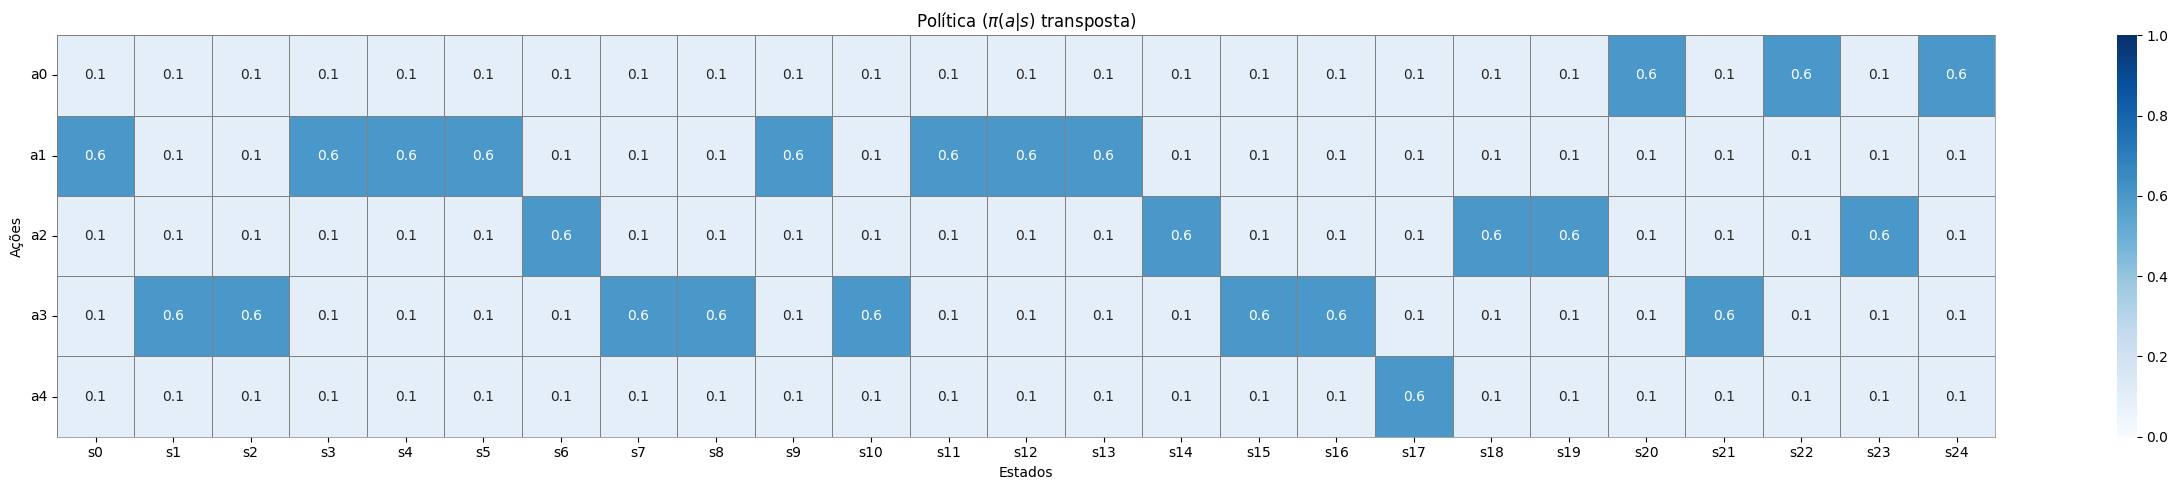

In [12]:
# Pi: ndarray (n_estados, n_acoes)
_ = plot_tabular(Pi, kind="Pi")

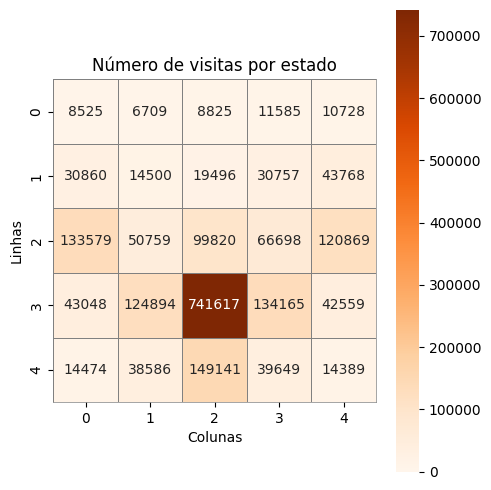

In [13]:
# Número de visitas por estado (soma sobre as ações)
_ = plot_tabular(numero_de_visitas, kind="VISITAS_ESTADO", ambiente=ambiente)

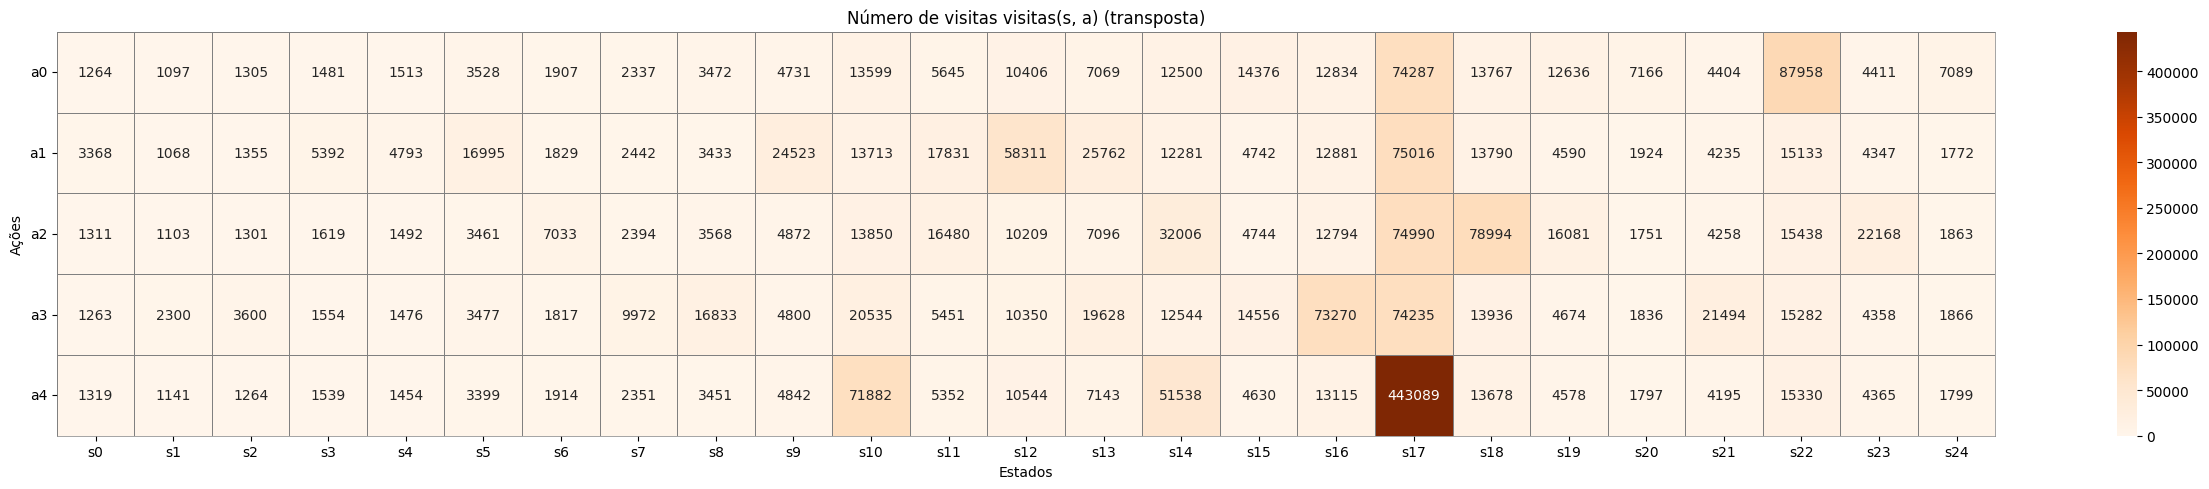

In [14]:
# Número de visitas por par (s,a)
_ = plot_tabular(numero_de_visitas, kind="VISITAS")

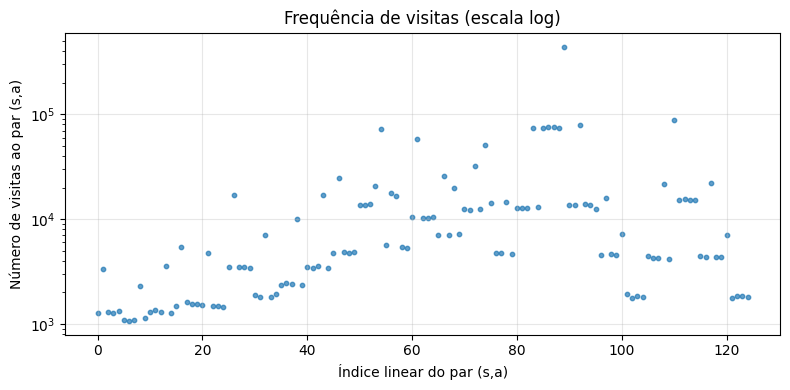

In [15]:
# Número de visitas por par (s,a)
_ = plot_visitas_log(numero_de_visitas)

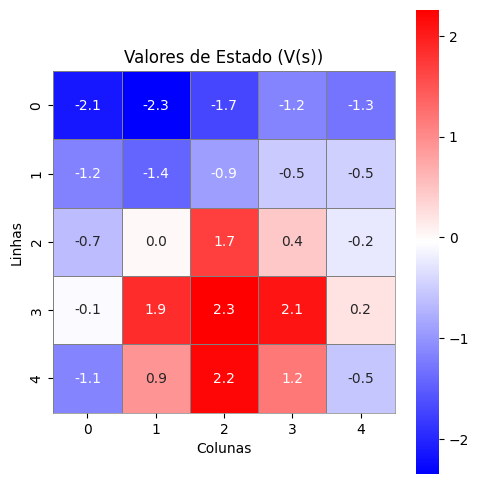

In [16]:
# V: ndarray (n_estados,)
_ = plot_tabular(V, kind="V", ambiente=ambiente, center_zero=False)

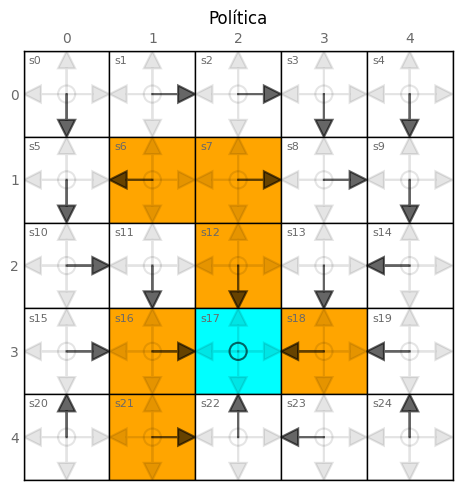

In [17]:
# Política (setas) sobre o ambiente
_ = plot_policy(ambiente, Pi)

# Tarefa (em trios):

0. Implementação
- Implemente as funções `gerar_trajetoria_epsilon` e `mc_epsilon_guloso` e reporte os resultados sobre a configuração base.
- Observe a figura da política. Em quantos estados a seta mais escura aponta na direção do alvo? Compare com o heatmap de $\pi(a\mid s)$: qual a probabilidade da ação preferida e qual a das demais?
- Observe os gráficos de visitas. Qual par $(s,a)$ foi o mais visitado e quantas visitas? Usando a matriz `numero_de_visitas`, calcule a mediana e o mínimo de visitas por par. Algum par ficou sem visitas?

1. Efeito do número de episódios ($N$)
- Fixe $\gamma = 0.9$, `T = 100_000` e $\epsilon = 0.5$, mantenha os demais parâmetros do baseline e execute o MC $\epsilon$-guloso para `N` $\in \{1,\ 10,\ 20,\ 50\}$.
- Descreva como $V$ e a política mudam à medida que `N` cresce.
- Compare os gráficos de visitas. Com `N = 1`, a cobertura dos pares $(s,a)$ já é suficiente?

2. Efeito do comprimento do episódio ($T$)
- Fixe $\gamma = 0.9$, `N = 20` e $\epsilon = 0.5$, mantenha os demais parâmetros do baseline e execute o MC $\epsilon$-guloso para `T` $\in \{100,\ 1000,\ 10000,\ 100000\}$.
- Descreva como $V$ e a política mudam à medida que `T` cresce.
- Compare os gráficos de visitas dos quatro valores. Como a distribuição das visitas muda com `T`?

3. Efeito do parâmetro $\epsilon$
- Fixe $\gamma = 0.9$, `N = 20` e `T = 100_000`, mantenha os demais parâmetros do baseline e execute o MC $\epsilon$-guloso para $\epsilon \in \{0.0,\ 0.25,\ 0.5,\ 0.75,\ 1.0\}$.
- Descreva como a política muda à medida que $\epsilon$ cresce, observando a opacidade das setas e o heatmap de $\pi(a\mid s)$.
- Compare os gráficos de visitas. Como $\epsilon$ afeta a cobertura dos pares $(s,a)$?
- Os extremos merecem atenção. Com $\epsilon = 0$, o que sobra de exploração no algoritmo? Com $\epsilon = 1$, o que a política aprendida recomenda fazer em cada estado?
- **Observação**: Com $\epsilon = 0$ a política deixa de ser $\epsilon$-suave e passa a ser determinística gulosa.

4. Comparação com o MC com inícios exploratórios
- Execute a função `mc_inicios_exploratorios` do Laboratório 5 **nesta instância do ambiente**, com `N = 20`, `T = 100_000` e $\gamma = 0.9$, e compare com o baseline do MC $\epsilon$-guloso. Guarde os resultados em variáveis com outros nomes para não sobrescrever `V`, `Q` e `Pi`.
- Compare os gráficos de visitas dos dois algoritmos. Algum par $(s,a)$ ficou sem nenhuma visita? Em qual dos dois algoritmos?
- Os dois algoritmos simulam o mesmo número de passos. O que, no funcionamento de cada um, explica a diferença de cobertura?
- Execute o MC com inícios exploratórios mais uma vez, agora com `N = 20_000` e `T = 100`, que mantém o total de passos. O que muda? O que isso indica sobre a comparação anterior?

**Configuração base (baseline)**

- `world_size = (5, 5)`
- `target_states = [(3, 2)]`
- `bad_states = [(1, 1), (1, 2), (2, 2), (3, 1), (3, 3), (4, 1)]`
- `allow_bad_entry = True`
- recompensas base: $[\,r_{\text{boundary}},\ r_{\text{bad}},\ r_{\text{target}},\ r_{\text{other}}\,] = [-1,\ -1,\ 1,\ 0]$
- fator de desconto: $\gamma = 0.9$
- número de episódios: `N = 20`
- comprimento do episódio: `T = 100_000`
- parâmetro epsilon: $\epsilon = 0.5$
- semente: `seed = 0`

**Mostrar:**

1. **Figuras**:
   - para a configuração base: heatmap de $V(s)$ no grid $(n_{\text{rows}}\times n_{\text{cols}})$, heatmap de $Q(s,a)$ (ações nas linhas, estados nas colunas), heatmap de $\pi(a\mid s)$ (probabilidades), a política desenhada com `plot_policy` e o número de visitas por par $(s,a)$ e por estado;
   - para os itens 1, 2 e 3: heatmap de $V(s)$, `plot_policy` e o gráfico de visitas, para cada valor testado;
   - para o item 4: `plot_policy` e o gráfico de visitas, para cada uma das três execuções.
2. **Discussão**: texto breve (3–6 linhas) por item.

**Entregáveis:**

Os entregáveis são **cumulativos ao longo da Unidade 1**. Ao final da unidade,
você entregará **apenas dois arquivos**, reunindo todos os laboratórios:

1. **Notebook** (`.ipynb`) — um único notebook com o código de todos os
   laboratórios da unidade, cada um em sua própria seção, na ordem em que foram
   realizados.

   O notebook deve **executar do início ao fim sem erros**, em um kernel novo,
   com *Restart & Run All*. Antes de entregar, execute-o dessa forma e confirme
   que todas as células rodam na ordem em que aparecem e que as saídas exibidas
   correspondem a essa execução. Notebooks que não executarem por completo serão
   penalizados.

2. **Relatório** (`.pdf`) — um único PDF, também organizado em seções, uma por
   laboratório.

   Este laboratório corresponde à **Seção 6 — MC $\epsilon$-guloso**, com
   uma subseção para cada um dos itens da tarefa. Cada subseção deve conter:

  - **Setup**: parâmetros utilizados. Se algum parâmetro do baseline for
  alterado, registre a alteração explicitamente.
  - **Resultados**: figuras e tabelas do experimento.
  - **Análise**: texto breve (3-6 linhas).

Nos próximos laboratórios da unidade, acrescente uma nova seção a cada arquivo,
preservando as anteriores.

O relatório **não** deve conter código.

A entrega é **única por grupo**. Identifique os integrantes no início do
notebook e na primeira página do relatório.

# Respostas

## 0. Implementação

Observando a figura da política, em todos os estados a seta mais escura aponta na direção do alvo. Comparando com o heatmap de  π(a∣s), a probabilidade da ação preferida é 0.6 (60%) e a das demais é 0.1 (10%).

In [18]:
print("Mínimo de visitas:", np.min(numero_de_visitas))
print("Mediana de visitas:", np.median(numero_de_visitas))

Mínimo de visitas: 1068.0
Mediana de visitas: 4793.0


Observando os gráficos de visitas, o par $(s,a)$ mais visitado foi o estado s17 com a ação a4, recebendo 443.089 visitas. Nenhum par ficou sem visitas

## 1. Efeito do número de episódios ( 𝑁 )


Executando MC epsilon-guloso com N = 1


Episódios (MC epsilon-guloso):   0%|          | 0/1 [00:00<?, ?it/s]

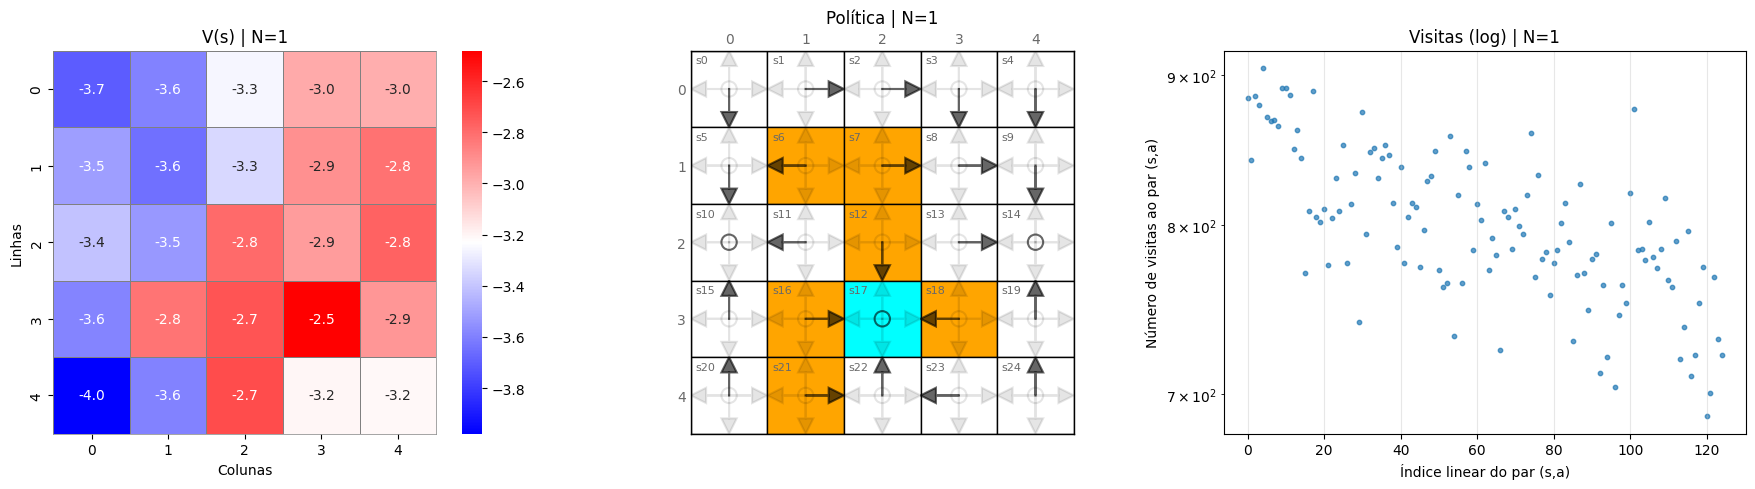

-> Mínimo de visitas para N=1: 688.0

Executando MC epsilon-guloso com N = 10


Episódios (MC epsilon-guloso):   0%|          | 0/10 [00:00<?, ?it/s]

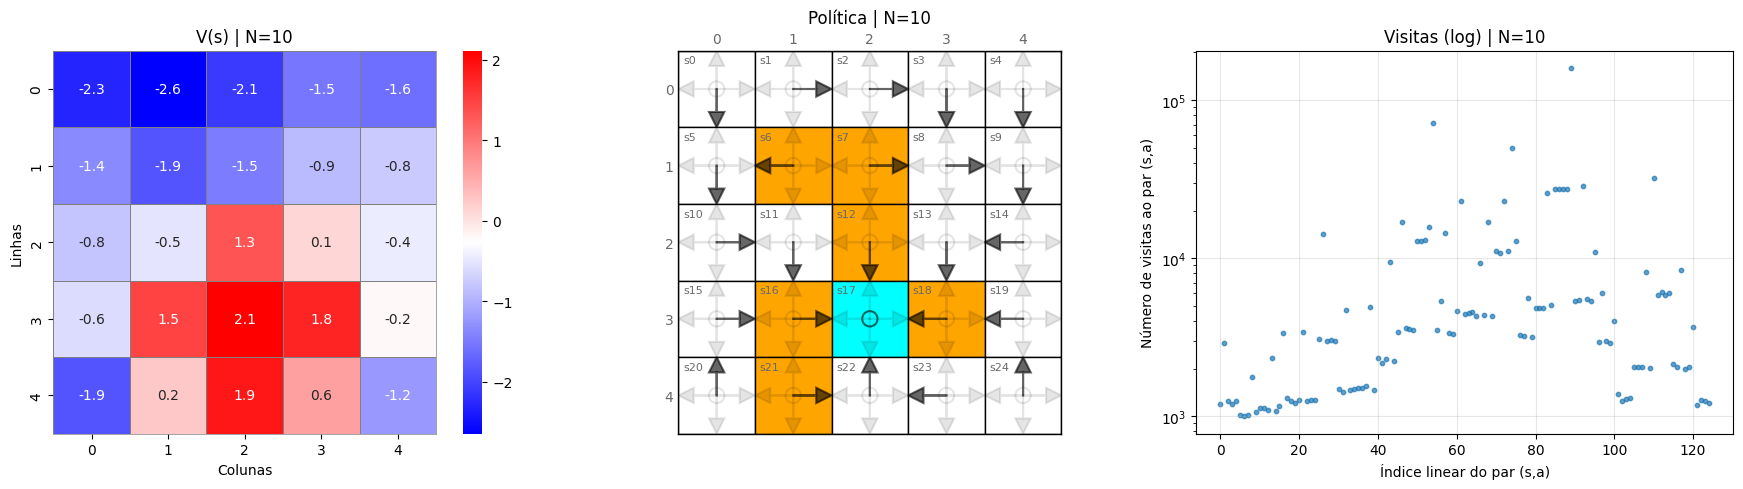

-> Mínimo de visitas para N=10: 998.0

Executando MC epsilon-guloso com N = 20


Episódios (MC epsilon-guloso):   0%|          | 0/20 [00:00<?, ?it/s]

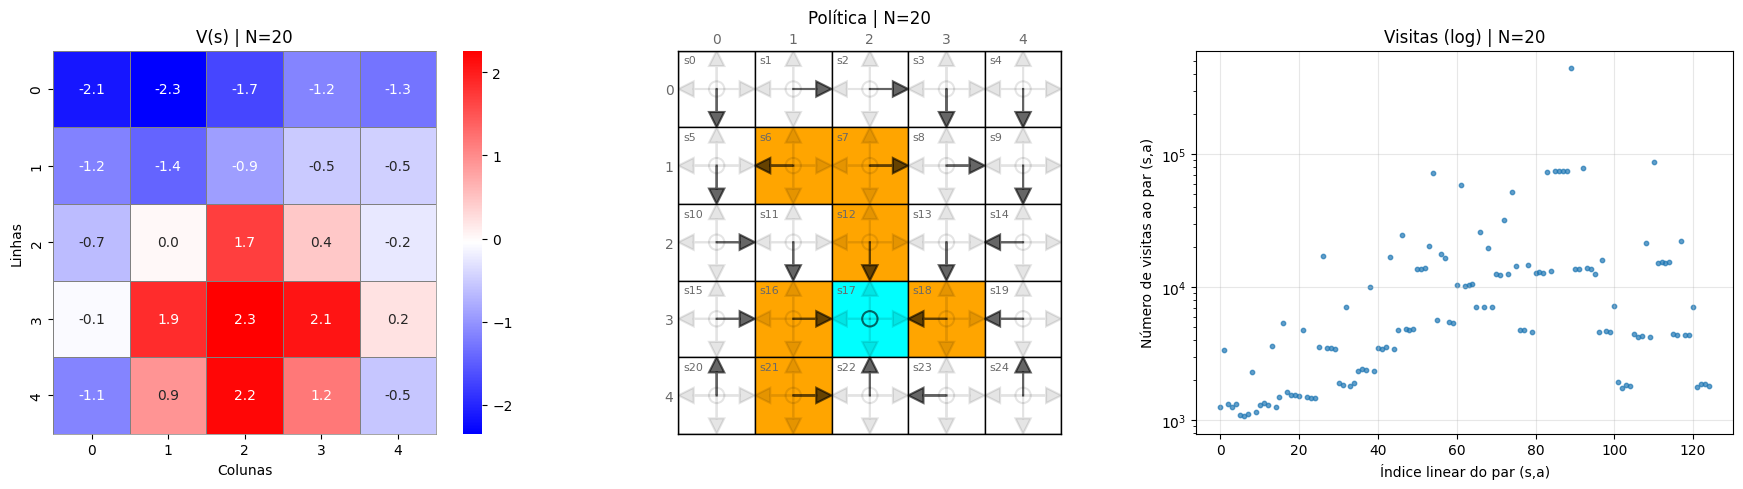

-> Mínimo de visitas para N=20: 1068.0

Executando MC epsilon-guloso com N = 50


Episódios (MC epsilon-guloso):   0%|          | 0/50 [00:00<?, ?it/s]

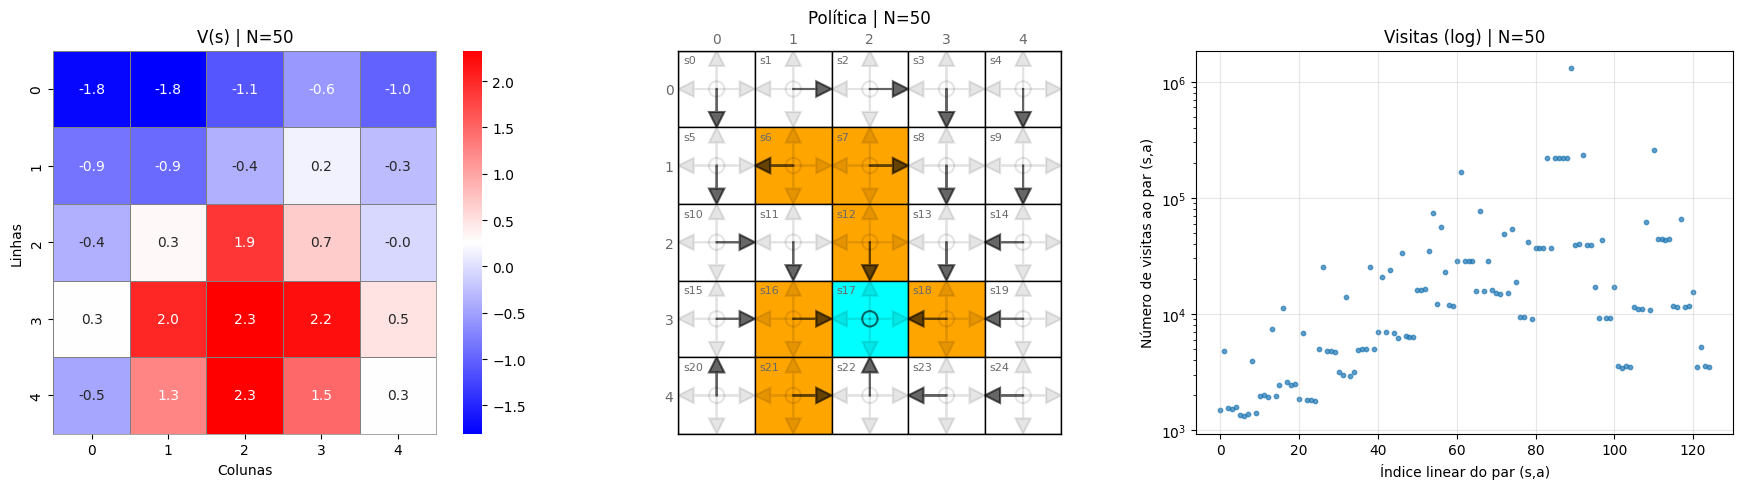

-> Mínimo de visitas para N=50: 1309.0


In [20]:
N_valores = [1, 10, 20, 50]

for n in N_valores:
    print(f"\n{'='*50}")
    print(f"Executando MC epsilon-guloso com N = {n}")
    print(f"{'='*50}")

    Q_n, Pi_n, visitas_n, k_n = mc_epsilon_guloso(
        ambiente,
        gamma=0.9,
        N=n,
        T=100_000,
        eps=0.5,
        seed=0
    )

    V_n = np.sum(Pi_n * Q_n, axis=1)

    fig, axs = plt.subplots(1, 3, figsize=(18, 5))

    plot_tabular(V_n, kind="V", ambiente=ambiente, center_zero=False, ax=axs[0])
    axs[0].set_title(f"V(s) | N={n}")

    plot_policy(ambiente, Pi_n, ax=axs[1], titulo=f"Política | N={n}")

    plot_visitas_log(visitas_n, ax=axs[2])
    axs[2].set_title(f"Visitas (log) | N={n}")

    plt.tight_layout()
    plt.show()
    print(f"-> Mínimo de visitas para N={n}: {np.min(visitas_n)}")